# Data modeling: day-ahead SARIMAX forecast of the hourly capacity factor (G3)

**Goal G3 (README):** a day-ahead SARIMAX forecast of the hourly capacity factor that only uses information available the day before, translated to Lucerne via its installed capacity.

| What | Value (test year 2025, from `combined_eda.ipynb`, Q17) |
|---|---|
| Reference (a): same hour of the previous day | MAE 27.6 % |
| Reference (b): radiation forecast × one factor per month | MAE 16.3 % |
| **Target** | skill ≥ 10 % against (b), i.e. **MAE ≤ 14.7 %** |

*MAE in % = mean absolute error divided by the mean capacity factor of the same hours (EDA Q17). Skill = 1 − MAE(model) / MAE(reference).*

**The question of this notebook:** which SARIMAX model, chosen without looking at the test year? The test year 2025 is not used here; it is used once in `04_evaluation.ipynb`.

| Part | Content |
|---|---|
| | The model in one equation: what every parameter means |
| **A** | Identification: M1 stationarity, M2 ACF/PACF, M3 which autocorrelation a forecast made the day before can use |
| **B** | Selection on the validation year 2024: M4 inputs, M5 error model |
| **C** | Final model on 2019–2024: M6 coefficients, M7 residual diagnostics |

Every question ends with **Finding → Consequence**. A decision log is at the end.

**Input:** `data/processed/modeling_dataset.csv` from `02_data_preparation.ipynb` (features, model inputs, periods). **Code:** `src/data_modeling.py`. **Figures:** `figures/modeling/`. **Run time:** about 5 minutes the first time (seven models are fitted on up to 52,000 hours, about 2 GB of memory), then about 1 minute, because the fitted parameters are cached in `data/processed/models/` (set `REFIT = True` to fit again).

*Developed with AI assistance (Claude).*

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

sys.path.insert(0, "..")   # project root, for src/
from src import data_modeling as dm
from src import data_preparation as dp
from src.plot_style import BLUE, GREY, ORANGE, save_figure   # one style for all notebooks

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*(Maximum Likelihood|InterpolationWarning|p-value|currently returns a plain tuple).*")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

TZ = dp.TZ
REFIT = False   # True: fit every model again instead of loading it from data/processed/models/

data = dp.load_modeling_dataset()
print(f"{len(data):,} hours × {data.shape[1]} columns")
data["period"].value_counts().reindex(list(dp.PERIODS)).to_frame("hours")

61,368 hours × 45 columns


,hours
period,
training,43824
warm-up,456
validation,8328
test,8760


## The model in one equation

SARIMAX is a **linear regression whose errors follow a seasonal ARIMA process**. For hour $t$:

$$y_t = x_t^\top \beta + u_t, \qquad \phi_p(B)\,\Phi_P(B^{s})\,(1-B)^d\,(1-B^{s})^D\,u_t = \theta_q(B)\,\Theta_Q(B^{s})\,\varepsilon_t$$

$y_t$ is the capacity factor, $x_t$ the 11 inputs of `02_data_preparation.ipynb` (all known the day before), $u_t$ the part the inputs do not explain, $\varepsilon_t$ the new, unforeseeable part of each hour. $B$ shifts back by one hour ($B\,u_t = u_{t-1}$, $B^{24} u_t = u_{t-24}$).

| Parameter | Name | Meaning in our data | Chosen |
|---|---|---|---|
| $s$ | season length | the daily rhythm: 24 hours | 24 (EDA Q8) |
| $d$, $D$ | (seasonal) differencing, the "I" | subtract the hour before ($d$) or the same hour yesterday ($D$) to remove a trend | 0, 0 (M1) |
| $p$, $\phi$ | AR order and coefficients | error of the hour(s) before carries over | 0 (M3, M5) |
| $q$, $\theta$ | MA order and coefficients | a past shock $\varepsilon$ carries over | 0 (M2) |
| $P$, $\Phi$ | seasonal AR order and coefficient | share of yesterday's error at the same hour that carries over (fog, haze, snow periods) | 1 (M5) |
| $Q$, $\Theta$ | seasonal MA order and coefficient | a shock of the same hour yesterday carries over | 0 (M2) |
| $\beta$ | coefficients of the inputs, the "X" | how radiation, the sun and yesterday's signals convert into capacity factor | 11, estimated (M6) |
| $\sigma^2$ | variance of $\varepsilon_t$ | size of the unforeseeable part | estimated (M6) |

The final model is SARIMAX(0,0,0)(1,0,0)₂₄, i.e. $y_t = x_t^\top \beta + u_t$ with $u_t = \Phi_1\,u_{t-24} + \varepsilon_t$.

**Estimation:** maximum likelihood with the Kalman filter (`statsmodels`). Night hours have no target (`02`, features) and are skipped by the filter; the forecast is 0 there. Start values from iterated least squares (`dm.start_values`) keep the fit short.

**Day-ahead forecast:** every day at midnight, the model state is updated with everything observed until then, and the 24 hours of the next day are forecast with the inputs of that day (`dm.day_ahead_forecast`). The parameters stay fixed.

# Part A · Identification: which SARIMA error structure?

Box–Jenkins: first remove what the inputs explain, then look at the rest $u_t$. For this, the regression part (inputs "physics") is fitted with ordinary least squares on 2019–2023, daylight hours only. Night hours get a residual of 0.

In [2]:
X_phys = data[dp.FEATURE_SETS["physics"]]
h = data.loc["2019":"2023"]
ok = X_phys.loc[h.index].notna().all(axis=1) & h["target"].notna()
ols = sm.OLS(h.loc[ok, "target"], X_phys.loc[h.index][ok]).fit()
resid = (h["target"] - X_phys.loc[h.index] @ ols.params).where(ok)
resid_filled = resid.fillna(0)   # night = 0 (the night is not modelled)
print(f"OLS on {ok.sum():,} daylight hours, R² = {ols.rsquared:.3f}, residual std = {resid.std():.4f}")

OLS on 21,918 daylight hours, R² = 0.980, residual std = 0.0399


## M1: Is the series stationary, or does it need differencing ($d$, $D$)?

Two tests with opposite null hypotheses: **ADF** (H0: unit root, i.e. not stationary) and **KPSS** (H0: stationary). Stationary means both agree (ADF p < 0.05, KPSS p > 0.05).

In [3]:
def tests(series, name):
    adf = adfuller(series.values, maxlag=48, autolag=None)
    kp = kpss(series.values, regression="c", nlags=48)
    return {"series": name, "ADF statistic": adf[0], "ADF p": adf[1], "KPSS statistic": kp[0], "KPSS p (0.1 means ≥ 0.1)": kp[1]}


cf_hist = h["capacity_factor"].ffill()
stationarity = pd.DataFrame([
    tests(cf_hist, "capacity factor, 2019–2023"),
    tests(resid_filled, "residual after the inputs (u_t)"),
    tests(resid.resample("D").mean().dropna(), "residual, daily mean"),
]).set_index("series")
yearly = resid.groupby(resid.index.year).agg(["mean", "std"])
display(stationarity.round(4))
yearly.round(4).T

,ADF statistic,ADF p,KPSS statistic,KPSS p (0.1 means ≥ 0.1)
series,,,,
"capacity factor, 2019–2023",-10.8935,0.0,0.9031,0.0100
residual after the inputs (u_t),-19.0379,0.0,1.7577,0.0100
"residual, daily mean",-5.1055,0.0,0.3507,0.0984


time_local,2019,2020,2021,2022,2023
mean,0.0003,0.0043,-0.0045,-0.0030,-0.0068
std,0.0446,0.0357,0.0450,0.0355,0.0370


> **Finding:** ADF rejects a unit root clearly for all three series (p < 0.001). KPSS rejects stationarity for the two hourly series (p = 0.01) but not for the daily mean of the residual (p ≈ 0.10). The hourly rejection comes from the daily rhythm of the spread (the residual is larger at noon than in the morning), not from a trend: the yearly mean of the residual stays between −0.007 and +0.004, its standard deviation between 0.036 and 0.045.
>
> **Consequence:** no differencing (d = 0, D = 0). The daily and the seasonal cycle are deterministic (position of the sun) and are handled by the inputs; differencing would remove exactly this information. The changing spread is a limitation for the error model (M7), not a reason to difference.

## M2: ACF and PACF of the residual: which orders $p$, $q$, $P$, $Q$?

The **ACF** (autocorrelation) shows how strongly the residual is linked to itself $k$ hours earlier. The **PACF** (partial autocorrelation) shows the same link after removing what the hours in between already explain. An AR process shows a PACF that stops after its order and an ACF that decays; an MA process the other way round.

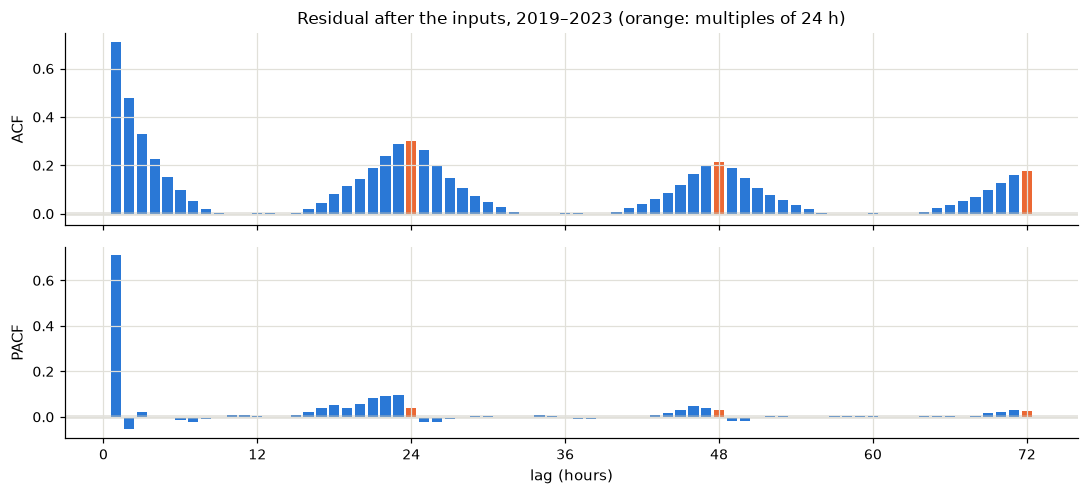

lag (h),1,2,3,23,24,25,48,72
ACF,0.711,0.478,0.329,0.290,0.302,0.263,0.215,0.176
PACF,0.711,-0.055,0.020,0.099,0.037,-0.023,0.032,0.027


In [4]:
lags = 72
r_acf = acf(resid_filled, nlags=lags, fft=True)
r_pacf = pacf(resid_filled, nlags=lags, method="ols")
band = 1.96 / np.sqrt(len(resid_filled))
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
for ax, values, name in [(axes[0], r_acf, "ACF"), (axes[1], r_pacf, "PACF")]:
    ax.bar(range(1, lags + 1), values[1:], color=[ORANGE if k % 24 == 0 else BLUE for k in range(1, lags + 1)], width=0.8)
    ax.axhspan(-band, band, color=GREY, alpha=0.4, linewidth=0)
    ax.set_ylabel(name)
axes[0].set_title("Residual after the inputs, 2019–2023 (orange: multiples of 24 h)")
axes[1].set_xlabel("lag (hours)")
axes[1].set_xticks(range(0, lags + 1, 12))
plt.tight_layout()
save_figure(fig, "residual_acf_pacf", phase="modeling")
plt.show()
pd.DataFrame({"ACF": r_acf[[1, 2, 3, 23, 24, 25, 48, 72]], "PACF": r_pacf[[1, 2, 3, 23, 24, 25, 48, 72]]},
             index=[1, 2, 3, 23, 24, 25, 48, 72]).rename_axis("lag (h)").round(3).T

> **Finding:** the residual ACF is **0.71 at lag 1** and decays like an AR(1) (0.48, 0.33, …). Around lag 24 there is a second, weaker hump (0.29–0.30 at 23–24 h, 0.22 at 48 h). The PACF is 0.71 at lag 1 and below 0.1 everywhere else: once the hour before is known, the day before adds little *for a forecast one hour ahead*. No sign of an MA term (the PACF does not decay).
>
> **Consequence:** q = Q = 0. For one-hour-ahead forecasts AR(1) would be enough. M3 checks what a forecast made at midnight can use; the candidates are AR(1) and a seasonal AR(1) at lag 24.

## M3: Which of this autocorrelation can a forecast made the day before actually use?

SARIMAX estimates its parameters by maximising the likelihood of **one-hour-ahead** forecasts. Our forecast is made at midnight for the whole next day: a daylight hour lies **8 to 20 hours** after the last observation, and that observation is a night hour. What matters is how strongly the residual of hour *h* on day D is linked to what is **known at midnight**.

In [5]:
R = pd.DataFrame({"r": resid, "day": resid.index.tz_localize(None).normalize(), "hour": resid.index.hour})
wide = R.pivot_table(index="day", columns="hour", values="r").asfreq("D")
yesterday = wide.shift(1)
rows = {}
for hour in range(8, 17):
    rows[hour] = {"1 h before (not known)": wide[hour].corr(wide[hour - 1]),
                  "same hour yesterday (known)": wide[hour].corr(yesterday[hour]),
                  "15:00 yesterday (known)": wide[hour].corr(yesterday[15]),
                  "steps from midnight": hour + 1}
usable = pd.DataFrame(rows).T
phi = r_acf[1]
usable["AR(1) carried over from midnight, φ^steps"] = phi ** usable["steps from midnight"]
usable.rename_axis("hour").round(3)

,1 h before (not known),same hour yesterday (known),15:00 yesterday (known),steps from midnight,"AR(1) carried over from midnight, φ^steps"
hour,,,,,
8,0.755,0.243,0.250,9.0,0.046
9,0.749,0.302,0.321,10.0,0.033
10,0.772,0.347,0.334,11.0,0.023
11,0.753,0.353,0.298,12.0,0.017
12,0.767,0.309,0.257,13.0,0.012
13,0.753,0.288,0.228,14.0,0.008
14,0.690,0.281,0.243,15.0,0.006
15,0.705,0.221,0.221,16.0,0.004
16,0.671,0.223,0.206,17.0,0.003


> **Finding:** the residual of hour *h* is linked to the hour before at r ≈ 0.67–0.77, but this value is **not known** at midnight. Carried over from midnight, an AR(1) term keeps only 0.3–5 % of its effect (φ^steps). What **is** known goes with r ≈ 0.22–0.35: the same hour yesterday, or yesterday afternoon.
>
> **Consequence:** only a term that reaches back 24 hours can help a forecast made the day before. The seasonal AR(1) at lag 24 matches the task. The non-seasonal AR(1) mainly changes how the regression is estimated (M5).

# Part B · Model selection on the validation year 2024

**Protocol:** fit on 2019–2023, then forecast every day of 20.1.–31.12.2024 **day ahead** (state updated with the observations up to midnight, parameters fixed), with the real radiation forecast as input. This is exactly what happens in the test (fit up to 2024, forecast 2025). The test year 2025 is **not** used for any choice. The reference is (b), refitted on 2019–2023.

## M4: Which inputs? (error model fixed to "no dynamics", i.e. a regression)

In [6]:
TRAIN_VAL = slice("2019-01-01", "2023-12-31 23:00")
WARMUP = slice(*dp.PERIODS["warm-up"])                     # observed, but no forecast archived yet
val_truth = data.loc[slice(*dp.PERIODS["validation"]), "capacity_factor"].dropna()
val_daylight = data.loc[val_truth.index, "radiation_weighted"] > 20
val_reference = dm.monthly_factor_reference(data, "2019", "2023", val_truth.index)
REFERENCE = "reference (b): forecast × monthly factor"


def validate(name, columns, order=(0, 0, 0), seasonal_order=(0, 0, 0, 24), train=TRAIN_VAL):
    X, y = dm.model_inputs(data, columns)
    res = dm.fit_or_load(f"val_{name}", y.loc[train], X.loc[train], order, seasonal_order, refit=REFIT)
    state = res.results.extend(y.loc[WARMUP].values, exog=X.loc[WARMUP].values)
    p = dm.postprocess(dm.day_ahead_forecast(state, X, y, "2024-01-20", "2024-12-31"), data["clear_sky"])
    return res, p.reindex(val_truth.index)


def with_skill(scores):
    scores["skill vs (b), %"] = dm.skill(scores["MAE hourly, %"], scores.loc[REFERENCE, "MAE hourly, %"]) * 100
    return scores


val_predictions, val_info = {REFERENCE: val_reference}, {}
for name, columns in dp.FEATURE_SETS.items():
    res, p = validate(name.replace(" ", "_").replace("+", "and"), columns)
    val_predictions[f"regression: {name}"] = p
    val_info[f"regression: {name}"] = {"inputs": len(columns), "AIC (training)": res.aic}
val_scores = with_skill(dm.score_table(val_predictions, val_truth, val_daylight))
val_scores.join(pd.DataFrame(val_info).T).round(3)

,"MAE hourly, %","MAE daily, %","RMSE hourly, %","MAE Nov-Feb, %","MAE May-Aug, %",R² hourly,R² daylight,"skill vs (b), %",inputs,AIC (training)
reference (b): forecast × monthly factor,20.766,15.763,42.848,32.305,17.326,0.924,0.858,0.000,NaN,NaN
regression: radiation only,19.844,14.527,40.947,32.143,17.047,0.930,0.870,4.439,1.0,-69065.364
regression: physics,17.984,13.930,37.795,33.161,13.339,0.941,0.890,13.394,7.0,-78891.255
regression: physics + day before,17.696,13.598,36.859,29.909,13.532,0.944,0.895,14.782,11.0,-80576.110


> **Finding (validation 2024):** reference (b) has an hourly MAE of **20.8 %**. Radiation alone (one slope) gains little (19.8 %, skill 4 %). The sun-position inputs ("physics") bring it to **18.0 %** (skill 13 %), the day-before signals to **17.7 %** (skill 15 %); the AIC agrees with this order. The day-before signals help mainly in winter (November–February 29.9 % against 33.2 % with "physics" alone), the sun-position inputs mainly in summer (May–August 13.3–13.5 % against 17.3 %).
>
> **Consequence:** the inputs **"physics + day before"** (all eleven) are kept.

## M5: Which error model? AIC against the day-ahead error

Candidates from M2 and M3, all with the inputs chosen in M4:

| Model | Meaning |
|---|---|
| (0,0,0)(0,0,0)₂₄ | regression only, errors independent |
| (0,0,0)(1,0,0)₂₄ | error of hour *h* depends on the error at the same hour yesterday ($\Phi_1$) |
| (1,0,0)(1,0,0)₂₄ | in addition, on the error of the hour before ($\phi_1$) |

The **AIC** (Akaike information criterion) rewards a high likelihood and penalises extra parameters; lower is better. *To keep the run time short, the three error models are fitted on **2022–2023** only (17,500 hours instead of 43,800). The error structure needs less data than the conversion of radiation; the final model in Part C uses all years again.*

In [7]:
CHOSEN = "physics + day before"
candidates = {"(0,0,0)(0,0,0)24": ((0, 0, 0), (0, 0, 0, 24)),
              "(0,0,0)(1,0,0)24": ((0, 0, 0), (1, 0, 0, 24)),
              "(1,0,0)(1,0,0)24": ((1, 0, 0), (1, 0, 0, 24))}
error_models, error_info = {REFERENCE: val_reference}, {}
for label, (order, seasonal) in candidates.items():
    res, p = validate(f"{CHOSEN.replace(' ', '_').replace('+', 'and')}_{label}_2022-2023", dp.FEATURE_SETS[CHOSEN], order, seasonal,
                      train=slice("2022-01-01", "2023-12-31 23:00"))
    error_models[label] = p
    error_info[label] = {"AIC (training)": res.aic, "BIC (training)": res.bic,
                         "φ1 (1 h)": res.params[-3] if order[0] else np.nan,
                         "Φ1 (24 h)": res.params[-2] if seasonal[0] else np.nan}
error_scores = with_skill(dm.score_table(error_models, val_truth, val_daylight))
error_scores.join(pd.DataFrame(error_info).T).round(3)

,"MAE hourly, %","MAE daily, %","RMSE hourly, %","MAE Nov-Feb, %","MAE May-Aug, %",R² hourly,R² daylight,"skill vs (b), %",AIC (training),BIC (training),φ1 (1 h),Φ1 (24 h)
reference (b): forecast × monthly factor,20.766,15.763,42.848,32.305,17.326,0.924,0.858,0.000,NaN,NaN,NaN,NaN
"(0,0,0)(0,0,0)24",17.505,13.422,36.441,29.792,13.560,0.945,0.898,15.702,-34032.686,-33939.433,NaN,NaN
"(0,0,0)(1,0,0)24",16.564,12.375,34.830,25.867,13.160,0.950,0.906,20.235,-34505.873,-34404.849,NaN,0.281
"(1,0,0)(1,0,0)24",21.870,18.843,44.165,26.972,18.881,0.919,0.850,-5.318,-42399.660,-42290.864,0.86,0.222


> **Finding:** the **AIC prefers (1,0,0)(1,0,0)₂₄ by far** (−42,399 against −34,506; φ₁ = 0.86), but its day-ahead error is the **worst of all**: 21.9 %, worse even than reference (b) (20.8 %). The seasonal term alone lowers the error from 17.5 % to **16.6 %** (Φ₁ = 0.28, skill 20 %), in winter from 29.8 % to 25.9 %.
>
> **Consequence:** the AIC measures one-hour-ahead forecasts, not the day-ahead task (M3). The model is chosen by its day-ahead error on 2024: **SARIMAX(0,0,0)(1,0,0)₂₄**.

# Part C · The final model

SARIMAX(0,0,0)(1,0,0)₂₄ with the inputs "physics + day before", fitted on **2019–2024** (radiation measured until 19.1.2024, forecast afterwards). These parameters are used unchanged for the test year in `04_evaluation.ipynb`.

## M6: Do the coefficients make sense?

In [8]:
FINAL_ORDER, FINAL_SEASONAL = (0, 0, 0), (1, 0, 0, 24)
final_columns = dp.FEATURE_SETS[CHOSEN]
X, y = dm.model_inputs(data, final_columns)
TRAIN_FINAL = slice("2019-01-01", "2024-12-31 23:00")
final = dm.fit_or_load("final", y.loc[TRAIN_FINAL], X.loc[TRAIN_FINAL], FINAL_ORDER, FINAL_SEASONAL, standard_errors=True, refit=REFIT)
coefficients = pd.DataFrame({"coefficient": final.params, "std. error": final.bse, "p-value": final.pvalues},
                            index=final_columns + ["Φ1 (ar.S.L24)", "σ² (sigma2)"])
print(f"Hours used: {final.nobs:,} (daylight with target) | log-likelihood {final.llf:,.0f} | AIC {final.aic:,.0f} | converged: {final.converged}")
coefficients.round(4)

Hours used: 26,247 (daylight with target) | log-likelihood 47,725 | AIC -95,423 | converged: True


,coefficient,std. error,p-value
rad,0.4318,0.0053,0.0
rad_elev,0.3088,0.0115,0.0
rad_season_cos,0.1326,0.0036,0.0
rad_season_sin,0.0081,0.0013,0.0
rad_squared,-0.0837,0.0093,0.0
clear,0.1068,0.0023,0.0
clear_season_cos,-0.0457,0.0025,0.0
rad_yday_index,0.0648,0.0053,0.0
rad_yday_fog,-0.0539,0.0084,0.0
clear_yday_fog,0.0359,0.0053,0.0


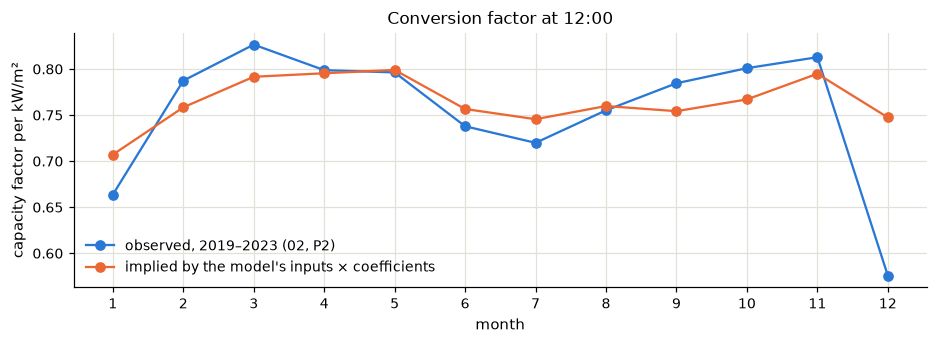

,1,2,3,4,5,6,7,8,9,10,11,12
observed,0.66,0.79,0.83,0.8,0.8,0.74,0.72,0.76,0.78,0.80,0.81,0.58
model,0.71,0.76,0.79,0.8,0.8,0.76,0.75,0.76,0.75,0.77,0.79,0.75


In [9]:
# What the coefficients mean: the conversion factor the regression part implies at 12:00 (sum of x·β / sum of radiation),
# on the same hours as the observed factor of 02_data_preparation.ipynb, P2 (2019-2023, measured radiation above 50 W/m²)
history = data.loc["2019":"2023"]
factor, _ = dp.conversion_factor(history)
light = history[history["radiation_weighted"] > 50].dropna(subset=["capacity_factor"])
noon = light[light.index.hour == 12]
b = pd.Series(final.params[:len(final_columns)], index=final_columns)
implied = dp.exog_matrix(noon, final_columns, "radiation_weighted").fillna(0) @ b
learned = implied.groupby(noon.index.month).sum() / noon["radiation_weighted"].groupby(noon.index.month).sum() * 1000

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(factor.index, factor[12], color=BLUE, marker="o", label="observed, 2019–2023 (02, P2)")
ax.plot(learned.index, learned.values, color=ORANGE, marker="o", label="implied by the model's inputs × coefficients")
ax.set_xticks(range(1, 13))
ax.set_xlabel("month")
ax.set_ylabel("capacity factor per kW/m²")
ax.set_title("Conversion factor at 12:00")
ax.legend()
save_figure(fig, "learned_conversion", phase="modeling")
plt.show()
pd.DataFrame({"observed": factor[12], "model": learned}).round(2).T

> **Finding:** all 11 coefficients and Φ₁ = **0.27** are clearly different from 0 (p < 0.001; with 26,000 hours almost everything is significant, so the signs matter more than the p-values). The signs make physical sense: a higher sun gives more output per radiation (`rad_elev` +0.31); saturation at high radiation (`rad_squared` −0.08); after a **cold winter day** the conversion drops (`rad_yday_cold` −0.15, snow on the panels lasts); after a **fog day** the forecast radiation is trusted less (`rad_yday_fog` −0.05) and more output is expected from the clear-sky part (`clear_yday_fog` +0.04, panels above the fog). Φ₁ = 0.27: about a quarter of yesterday's error at the same hour carries over. The figure checks whether inputs × coefficients reproduce the observed conversion at noon: from February to November they match within about 0.03. **In December the model assumes 0.75, while 0.58 is observed** (January 0.71 against 0.66).
>
> **Consequence:** the coefficients are plausible, not only useful for the error. One yearly cosine/sine cannot follow the sharp drop in December (low sun, snow, fog); the forecast is likely to be too high there, which the evaluation has to check per month.

## M7: Residual diagnostics. What does the model leave unexplained?

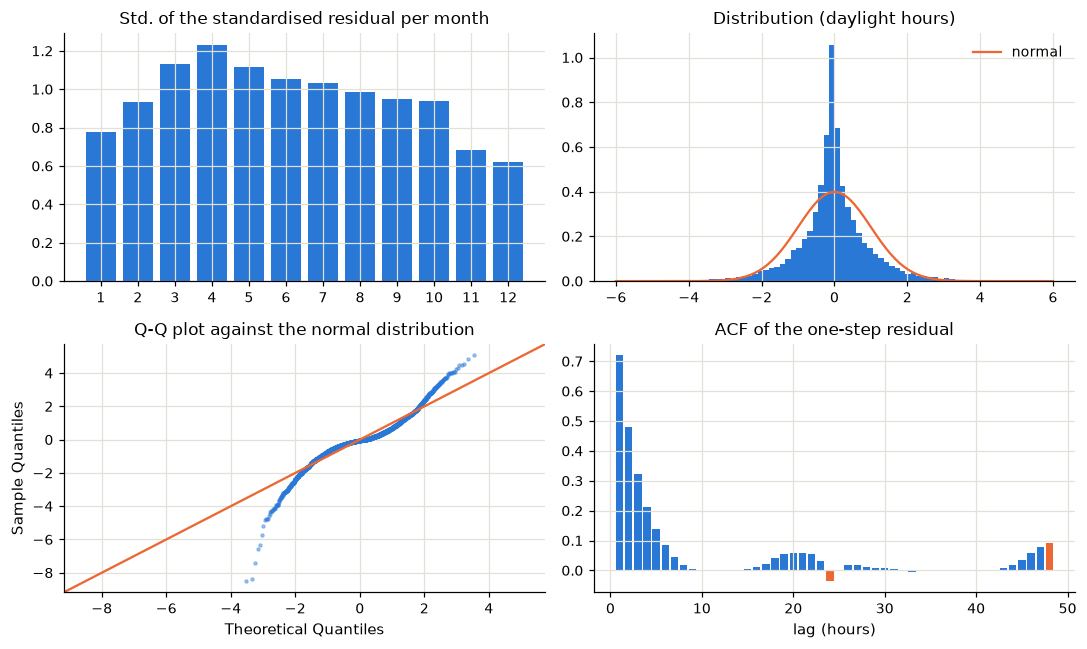

Skewness -0.13, excess kurtosis 4.5


,lb_stat,lb_pvalue
1,27232.3,0.0
24,49594.3,0.0
48,50661.6,0.0


In [10]:
# One-step residual of this model, computed directly: u = y - X·beta, e_t = u_t - Φ·u_(t-24), standardised by σ
beta, Phi, sigma2 = final.params[:len(final_columns)], final.params[-2], final.params[-1]
u = y.loc[TRAIN_FINAL] - X.loc[TRAIN_FINAL] @ beta
std_resid = (u - Phi * u.shift(24)) / np.sqrt(sigma2)
daylight_resid = std_resid.dropna()
lb = acorr_ljungbox(std_resid.fillna(0), lags=[1, 24, 48], return_df=True)

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
monthly_std = daylight_resid.groupby(daylight_resid.index.month).std()
axes[0, 0].bar(monthly_std.index, monthly_std.values, color=BLUE)
axes[0, 0].set_title("Std. of the standardised residual per month")
axes[0, 0].set_xticks(range(1, 13))
axes[0, 1].hist(daylight_resid.clip(-6, 6), bins=80, color=BLUE, density=True)
grid = np.linspace(-6, 6, 200)
axes[0, 1].plot(grid, np.exp(-grid ** 2 / 2) / np.sqrt(2 * np.pi), color=ORANGE, label="normal")
axes[0, 1].set_title("Distribution (daylight hours)")
axes[0, 1].legend()
sm.qqplot(daylight_resid.sample(5000, random_state=1), line="45", ax=axes[1, 0], markersize=2, alpha=0.4)
axes[1, 0].get_lines()[1].set_color(ORANGE)   # the 45° line in the common style
axes[1, 0].set_title("Q-Q plot against the normal distribution")
res_acf = acf(std_resid.fillna(0), nlags=48, fft=True)
axes[1, 1].bar(range(1, 49), res_acf[1:], color=[ORANGE if k % 24 == 0 else BLUE for k in range(1, 49)])
axes[1, 1].set_title("ACF of the one-step residual")
axes[1, 1].set_xlabel("lag (hours)")
plt.tight_layout()
save_figure(fig, "residual_diagnostics", phase="modeling")
plt.show()
print(f"Skewness {daylight_resid.skew():.2f}, excess kurtosis {daylight_resid.kurt():.1f}")
lb.round(1)

> **Finding:**
> - **Spread per month:** the standardised residual has a standard deviation of 1.1–1.2 from March to May but only 0.6–0.8 from November to January. The model assumes one constant σ², so its own prediction intervals would be **too narrow in spring and too wide in winter**.
> - **Distribution:** a sharp peak and heavy tails (excess kurtosis 4.5), with a longer tail to the negative side (the model forecast far too much: sudden clouds, fog, snow). Not normal.
> - **ACF:** large at lag 1 (0.72), as expected, because the link to the hour before was left out on purpose (M5); the Ljung–Box test therefore rejects white noise. At lag 24 the ACF is ≈ 0: Φ₁ has taken up the daily link.
>
> **Consequence:** the **point forecasts** are usable, the model's **intervals** are not; we do not report them. The evaluation reports the errors per season instead.

# Summary

| # | Finding | Consequence |
|---|---|---|
| M1 | ADF: no unit root; the KPSS rejection comes from the daily rhythm of the spread | d = D = 0 |
| M2 | Residual ACF decays like AR(1), PACF stops after lag 1; hump at 24 h | q = Q = 0; candidates AR(1), seasonal AR(1) |
| M3 | Residual linked to the hour before at 0.71 (not known at midnight), to yesterday at 0.22–0.35 (known) | seasonal AR at lag 24 |
| M4 | Validation 2024: physics + day-before inputs 17.7 % against 20.8 % for reference (b) | all eleven inputs kept |
| M5 | AIC prefers AR(1), whose day-ahead error is the worst (21.9 %); the seasonal AR alone 16.6 % (skill 20 %) | **SARIMAX(0,0,0)(1,0,0)₂₄** |
| M6 | All coefficients significant and physically plausible; Φ₁ = 0.27; December conversion assumed too high | model kept; check December in the evaluation |
| M7 | Point forecasts fine; spread changes with the season, heavy tails | no model intervals |

**Next:** `04_evaluation.ipynb` forecasts every day of the test year 2025 once with this model and compares it with references (a) and (b) (README section 5).

## Decision log

| Decision | Reason | Where |
|---|---|---|
| SARIMAX: regression on inputs known the day before, with SARIMA errors | classical, interpretable statistical model (course scope); the daily cycle enters through the inputs, the persistence of the weather through the error model | equation |
| No differencing | the deterministic cycles are in the inputs | M1 |
| No MA terms | ACF/PACF show an AR pattern | M2 |
| Model chosen by the day-ahead error on 2024, not by AIC | the AIC rewards one-hour-ahead skill (M3, M5) | M5 |
| Error models compared on 2022–2023 | run time; the final model uses all years | M5 |
| Final model fitted on 2019–2024 with fixed parameters for 2025 | no information of the test year enters the parameters | Part C |
| No prediction intervals from the model | spread changes with the season, errors not normal | M7 |